In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sqlalchemy

print("ApexPlanet Task 1 - Environment Ready!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

ApexPlanet Task 1 - Environment Ready!
Pandas: 3.1.1
NumPy: 2.5.5


In [4]:
import os

print("Current location:")
print(os.getcwd())

print("\nFiles inside raw folder:")
print(os.listdir("../data/raw"))

Current location:
C:\Users\forpc\Desktop\apexplanet-data-analytics\notebooks

Files inside raw folder:
[]


In [5]:
file_path = "../data/raw/sample_-_superstore.xls"

excel_file = pd.ExcelFile(file_path)

print("Available sheets:", excel_file.sheet_names)


C:\Users\forpc\AppData\Local\Temp\ipykernel_16504\2484669182.py:3: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  excel_file = pd.ExcelFile(file_path)


Available sheets: ['Orders', 'People', 'Returns']


In [6]:
df = pd.read_excel(file_path, sheet_name="Orders")

print("Dataset loaded successfully!")

C:\Users\forpc\AppData\Local\Temp\ipykernel_16504\305301092.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(file_path, sheet_name="Orders")


Dataset loaded successfully!


In [7]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [8]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 10194
Total Columns: 21


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [10]:
df.describe()

,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002943,2025-05-03 10:52:45.626839,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


In [11]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [12]:
print("Total duplicate rows:", df.duplicated().sum())


Total duplicate rows: 0


In [13]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [14]:
duplicate_percentage = (df.duplicated().sum() / len(df)) * 100

print("Duplicate percentage:", duplicate_percentage)

Duplicate percentage: 0.0


In [15]:
df.dtypes


Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country/Region               str
City                         str
State/Province               str
Postal Code               object
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
dtype: object

In [16]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Row ID,10194.0,5097.5,1.0,2549.25,5097.5,7645.75,10194.0,2942.898656
Order Date,10194,2025-04-29 11:48:25.002943,2023-01-03 00:00:00,2024-05-14 00:00:00,2025-06-25 00:00:00,2026-05-14 00:00:00,2026-12-30 00:00:00,NaN
Ship Date,10194,2025-05-03 10:52:45.626839,2023-01-07 00:00:00,2024-05-19 00:00:00,2025-06-28 00:00:00,2026-05-18 00:00:00,2027-01-05 00:00:00,NaN
Sales,10194.0,228.225854,0.444,17.22,53.91,209.5,22638.48,619.906839
Quantity,10194.0,3.791838,1.0,2.0,3.0,5.0,14.0,2.228317
Discount,10194.0,0.155385,0.0,0.0,0.2,0.2,0.8,0.206249
Profit,10194.0,28.673417,-6599.978,1.7608,8.69,29.297925,8399.976,232.465115


In [17]:
print("Unique Orders:", df["Order ID"].nunique())
print("Unique Customers:", df["Customer ID"].nunique())
print("Unique Products:", df["Product ID"].nunique())
print("Categories:", df["Category"].unique())
print("Regions:", df["Region"].unique())

Unique Orders: 5111
Unique Customers: 804
Unique Products: 1862
Categories: <StringArray>
['Office Supplies', 'Furniture', 'Technology']
Length: 3, dtype: str
Regions: <StringArray>
['Central', 'East', 'South', 'West']
Length: 4, dtype: str


In [18]:
print("========== DATA QUALITY REPORT ==========")

print("\n1. Missing Values:")
print(df.isnull().sum().sum())

print("\n2. Duplicate Rows:")
print(df.duplicated().sum())

print("\n3. Data Types:")
print(df.dtypes)

print("\n4. Statistical Summary:")
display(df.describe().T)

========== DATA QUALITY REPORT ==========

1. Missing Values:
0

2. Duplicate Rows:
0

3. Data Types:
Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country/Region               str
City                         str
State/Province               str
Postal Code               object
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
dtype: object

4. Statistical Summary:


,count,mean,min,25%,50%,75%,max,std
Row ID,10194.0,5097.5,1.0,2549.25,5097.5,7645.75,10194.0,2942.898656
Order Date,10194,2025-04-29 11:48:25.002943,2023-01-03 00:00:00,2024-05-14 00:00:00,2025-06-25 00:00:00,2026-05-14 00:00:00,2026-12-30 00:00:00,NaN
Ship Date,10194,2025-05-03 10:52:45.626839,2023-01-07 00:00:00,2024-05-19 00:00:00,2025-06-28 00:00:00,2026-05-18 00:00:00,2027-01-05 00:00:00,NaN
Sales,10194.0,228.225854,0.444,17.22,53.91,209.5,22638.48,619.906839
Quantity,10194.0,3.791838,1.0,2.0,3.0,5.0,14.0,2.228317
Discount,10194.0,0.155385,0.0,0.0,0.2,0.2,0.8,0.206249
Profit,10194.0,28.673417,-6599.978,1.7608,8.69,29.297925,8399.976,232.465115


In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns

print("Numeric Columns:")
print(numeric_cols.tolist())

Numeric Columns:
['Row ID', 'Sales', 'Quantity', 'Discount', 'Profit']


In [20]:
print("Negative Sales:", (df["Sales"] < 0).sum())

print("Negative Profit:", (df["Profit"] < 0).sum())

print("Zero Quantity:", (df["Quantity"] == 0).sum())

print("Negative Quantity:", (df["Quantity"] < 0).sum())

print("Discount below 0:", (df["Discount"] < 0).sum())

print("Discount above 1:", (df["Discount"] > 1).sum())

Negative Sales: 0
Negative Profit: 1901
Zero Quantity: 0
Negative Quantity: 0
Discount below 0: 0
Discount above 1: 0


In [21]:
print("Order Date:", df["Order Date"].dtype)
print("Ship Date:", df["Ship Date"].dtype)

print(
    "Ship date before order date:",
    (df["Ship Date"] < df["Order Date"]).sum()
)

Order Date: datetime64[us]
Ship Date: datetime64[us]
Ship date before order date: 0


In [22]:
for col in ["Sales", "Quantity", "Discount", "Profit"]:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{col}")
    print("Lower Bound:", lower)
    print("Upper Bound:", upper)
    print("Outliers:", len(outliers))


Sales
Lower Bound: -271.20000000000005
Upper Bound: 497.92
Outliers: 1183

Quantity
Lower Bound: -2.5
Upper Bound: 9.5
Outliers: 175

Discount
Lower Bound: -0.30000000000000004
Upper Bound: 0.5
Outliers: 874

Profit
Lower Bound: -39.54488749999997
Upper Bound: 70.60361249999997
Outliers: 1913


In [23]:
print("Unique Discount Values:")
print(sorted(df["Discount"].unique()))

Unique Discount Values:
[np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.32), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]


In [24]:
df.nlargest(10, "Sales")[
    ["Order ID", "Product Name", "Sales", "Profit"]
]

,Order ID,Product Name,Sales,Profit
226,US-2023-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1811.0784
5894,US-2025-118689,Canon imageCLASS 2200 Advanced Copier,17499.950,8399.9760
7255,US-2026-140151,Canon imageCLASS 2200 Advanced Copier,13999.960,6719.9808
9171,US-2026-127180,Canon imageCLASS 2200 Advanced Copier,11199.968,3919.9888
9517,US-2026-166709,Canon imageCLASS 2200 Advanced Copier,10499.970,5039.9856
6674,US-2025-117121,GBC Ibimaster 500 Manual ProClick Binding System,9892.740,4946.3700
1203,US-2023-116904,Ibico EPK-21 Electric Binding System,9449.950,4630.4755
4624,US-2025-107440,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930,2365.9818
4282,US-2025-158841,HP Designjet T520 Inkjet Large Format Printer ...,8749.950,2799.9840
4845,US-2025-143714,Canon imageCLASS 2200 Advanced Copier,8399.976,1119.9968


In [25]:
print("Highest Profit:")
display(df.nlargest(5, "Profit")[["Product Name", "Sales", "Profit"]])

print("Lowest Profit:")
display(df.nsmallest(5, "Profit")[["Product Name", "Sales", "Profit"]])

Highest Profit:


,Product Name,Sales,Profit
5894,Canon imageCLASS 2200 Advanced Copier,17499.95,8399.9760
7255,Canon imageCLASS 2200 Advanced Copier,13999.96,6719.9808
9517,Canon imageCLASS 2200 Advanced Copier,10499.97,5039.9856
6674,GBC Ibimaster 500 Manual ProClick Binding System,9892.74,4946.3700
1203,Ibico EPK-21 Electric Binding System,9449.95,4630.4755


Lowest Profit:


,Product Name,Sales,Profit
6398,Cubify CubeX 3D Printer Double Head Print,4499.985,-6599.9780
9318,Cubify CubeX 3D Printer Triple Head Print,7999.980,-3839.9904
821,GBC DocuBind P400 Electric Binding System,2177.584,-3701.8928
7441,Lexmark MX611dhe Monochrome Laser Printer,2549.985,-3399.9800
9845,Ibico EPK-21 Electric Binding System,1889.990,-2929.4845


In [26]:
print("Quantity distribution:")
print(df["Quantity"].value_counts().sort_index())

Quantity distribution:
Quantity
1      933
2     2440
3     2435
4     1212
5     1269
6      585
7      617
8      269
9      259
10      61
11      34
12      23
13      27
14      30
Name: count, dtype: int64


In [27]:
print(df["Discount"].value_counts().sort_index())

Discount
0.00    4925
0.10      96
0.15      52
0.20    3706
0.30     230
0.32      27
0.40     207
0.45      11
0.50      66
0.60     149
0.70     424
0.80     301
Name: count, dtype: int64


In [28]:
display(
    df.nlargest(10, "Sales")[
        ["Order ID", "Product Name", "Sales", "Discount", "Profit"]
    ]
)

,Order ID,Product Name,Sales,Discount,Profit
226,US-2023-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,0.5,-1811.0784
5894,US-2025-118689,Canon imageCLASS 2200 Advanced Copier,17499.950,0.0,8399.9760
7255,US-2026-140151,Canon imageCLASS 2200 Advanced Copier,13999.960,0.0,6719.9808
9171,US-2026-127180,Canon imageCLASS 2200 Advanced Copier,11199.968,0.2,3919.9888
9517,US-2026-166709,Canon imageCLASS 2200 Advanced Copier,10499.970,0.0,5039.9856
6674,US-2025-117121,GBC Ibimaster 500 Manual ProClick Binding System,9892.740,0.0,4946.3700
1203,US-2023-116904,Ibico EPK-21 Electric Binding System,9449.950,0.0,4630.4755
4624,US-2025-107440,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930,0.0,2365.9818
4282,US-2025-158841,HP Designjet T520 Inkjet Large Format Printer ...,8749.950,0.0,2799.9840
4845,US-2025-143714,Canon imageCLASS 2200 Advanced Copier,8399.976,0.4,1119.9968


In [29]:
display(
    df.nsmallest(10, "Profit")[
        ["Order ID", "Product Name", "Sales", "Discount", "Profit"]
    ]
)

,Order ID,Product Name,Sales,Discount,Profit
6398,US-2025-108196,Cubify CubeX 3D Printer Double Head Print,4499.985,0.7,-6599.9780
9318,US-2026-168116,Cubify CubeX 3D Printer Triple Head Print,7999.980,0.5,-3839.9904
821,US-2023-169019,GBC DocuBind P400 Electric Binding System,2177.584,0.8,-3701.8928
7441,US-2026-134845,Lexmark MX611dhe Monochrome Laser Printer,2549.985,0.7,-3399.9800
9845,US-2026-122714,Ibico EPK-21 Electric Binding System,1889.990,0.8,-2929.4845
4037,US-2024-147830,Cubify CubeX 3D Printer Double Head Print,1799.994,0.7,-2639.9912
9557,US-2026-131254,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,0.8,-2287.7820
2108,US-2024-116638,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,0.4,-1862.3124
4570,US-2025-130946,GBC DocuBind P400 Electric Binding System,1088.792,0.8,-1850.9464
226,US-2023-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,0.5,-1811.0784


In [30]:
print("Discount Distribution:")
print(df["Discount"].value_counts().sort_index())

Discount Distribution:
Discount
0.00    4925
0.10      96
0.15      52
0.20    3706
0.30     230
0.32      27
0.40     207
0.45      11
0.50      66
0.60     149
0.70     424
0.80     301
Name: count, dtype: int64


In [31]:
print("Minimum Discount:", df["Discount"].min())
print("Maximum Discount:", df["Discount"].max())

Minimum Discount: 0.0
Maximum Discount: 0.8


In [32]:
discount_analysis = df.groupby("Discount").agg(
    Total_Orders=("Order ID", "count"),
    Average_Sales=("Sales", "mean"),
    Average_Profit=("Profit", "mean"),
    Total_Profit=("Profit", "sum")
).round(2)

display(discount_analysis)

,Total_Orders,Average_Sales,Average_Profit,Total_Profit
Discount,,,,
0.00,4925,224.43,66.34,326718.59
0.10,96,572.42,94.79,9099.97
0.15,52,529.97,27.29,1418.99
0.20,3706,208.83,24.58,91079.95
0.30,230,454.24,-45.71,-10513.45
0.32,27,536.79,-88.56,-2391.14
0.40,207,562.79,-111.53,-23086.37
0.45,11,498.63,-226.65,-2493.11
0.50,66,892.71,-310.70,-20506.43


In [43]:
## Data Cleaning and Preprocessing

In [33]:
cleaned_df = df.copy()

print("Original Shape:", df.shape)
print("Cleaned Shape:", cleaned_df.shape)

Original Shape: (10194, 21)
Cleaned Shape: (10194, 21)


In [34]:
cleaned_df.columns = cleaned_df.columns.str.strip()

In [35]:
print(cleaned_df.dtypes)

Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
Country/Region               str
City                         str
State/Province               str
Postal Code               object
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
dtype: object


In [36]:
print("Missing Values:", cleaned_df.isnull().sum().sum())

print("Duplicate Rows:", cleaned_df.duplicated().sum())

print("Invalid Sales:", (cleaned_df["Sales"] < 0).sum())

print("Invalid Quantity:", (cleaned_df["Quantity"] <= 0).sum())

print("Invalid Discount:",
      ((cleaned_df["Discount"] < 0) |
       (cleaned_df["Discount"] > 1)).sum())

print("Invalid Dates:",
      (cleaned_df["Ship Date"] < cleaned_df["Order Date"]).sum())

Missing Values: 0
Duplicate Rows: 0
Invalid Sales: 0
Invalid Quantity: 0
Invalid Discount: 0
Invalid Dates: 0


In [37]:
import os

os.makedirs("../data/processed", exist_ok=True)

cleaned_df.to_csv(
    "../data/processed/cleaned_superstore.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [38]:
# Exploratory Data Analysis (EDA)

## 1. Univariate Analysis
## 2. Category-wise Sales Analysis
## 3. Region-wise Performance
## 4. Monthly Sales Trend
## 5. Profitability Analysis

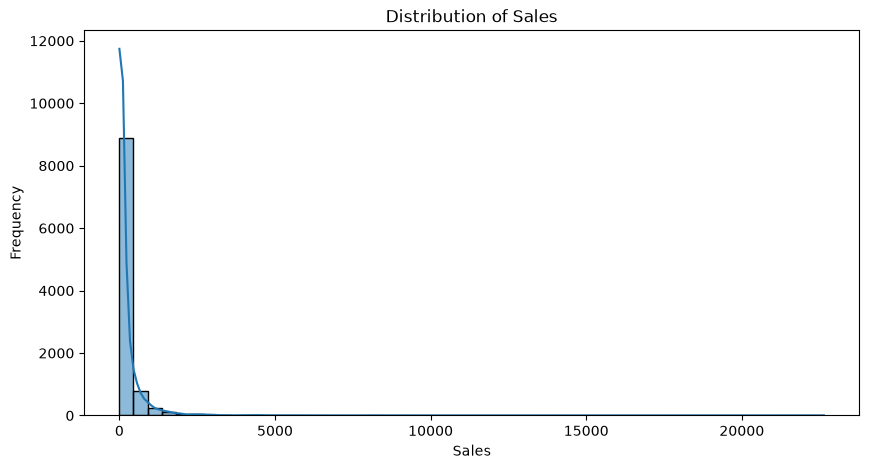

In [39]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=cleaned_df,
    x="Sales",
    bins=50,
    kde=True
)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

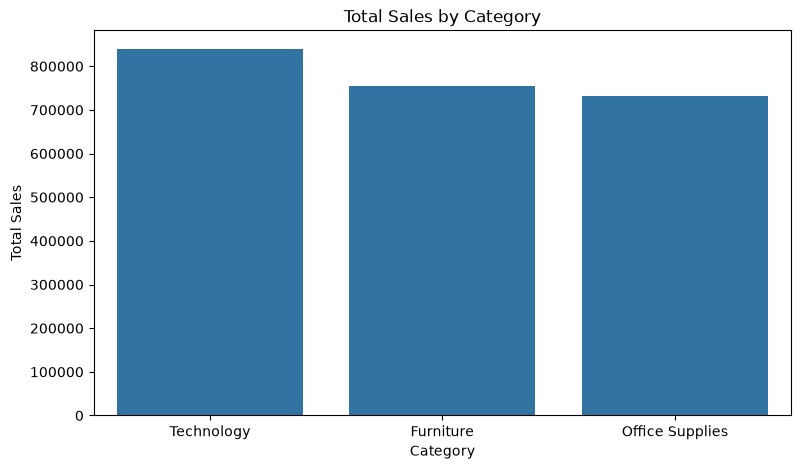

In [40]:
category_sales = cleaned_df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.show()

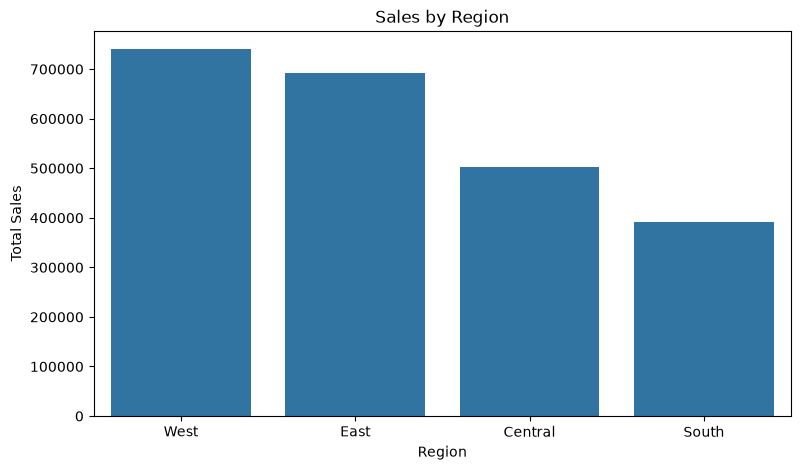

In [41]:
region_sales = cleaned_df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=region_sales.index,
    y=region_sales.values
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.show()

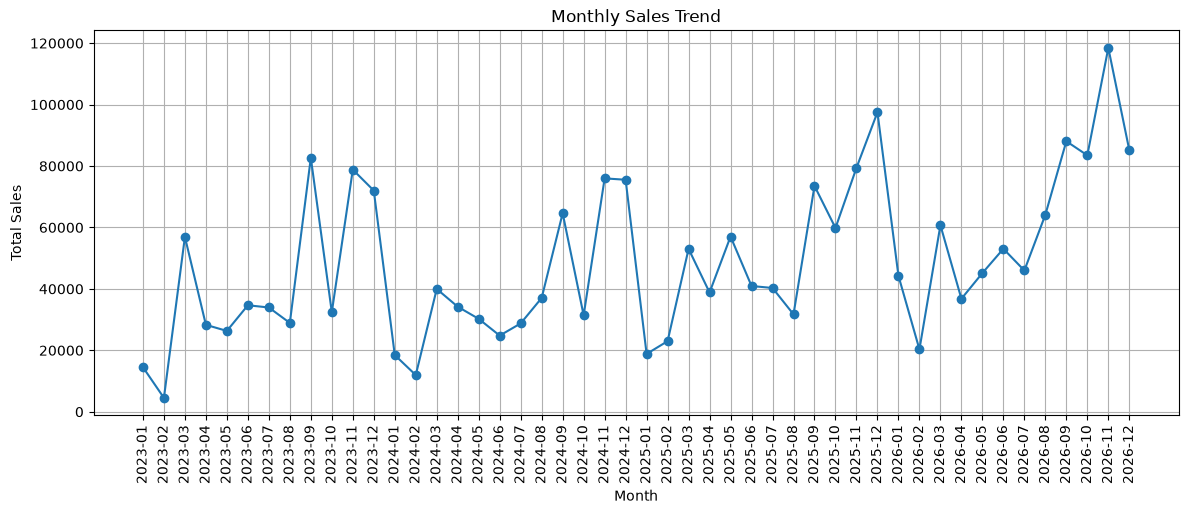

In [64]:
cleaned_df["Month"] = cleaned_df["Order Date"].dt.to_period("M")

monthly_sales = cleaned_df.groupby("Month")["Sales"].sum()

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)

plt.grid(True)
plt.savefig("../reports/figures/monthly_sales.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [45]:
## Profitability Analysis

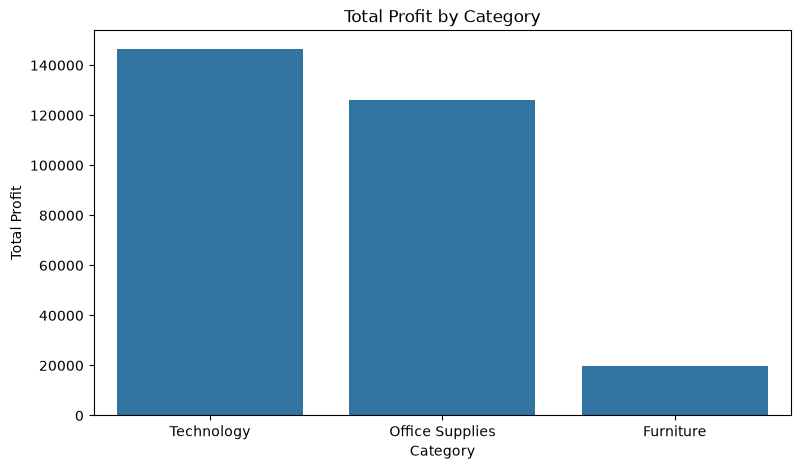

In [46]:
category_profit = cleaned_df.groupby("Category")["Profit"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title("Total Profit by Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")

plt.show()

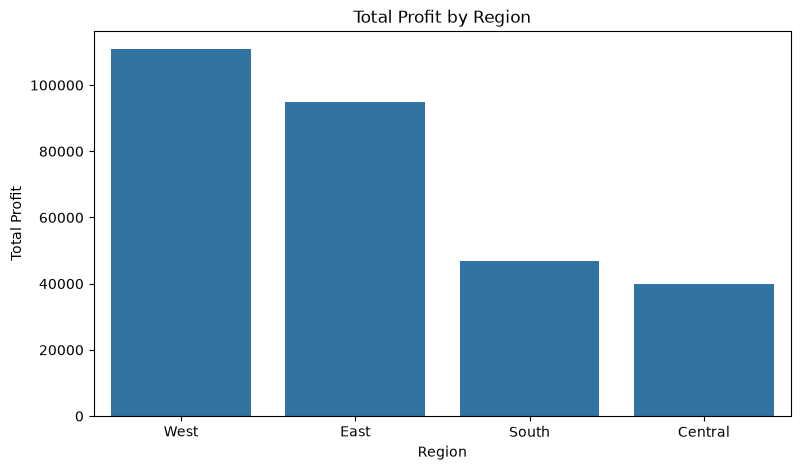

In [47]:
region_profit = cleaned_df.groupby("Region")["Profit"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=region_profit.index,
    y=region_profit.values
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")

plt.show()

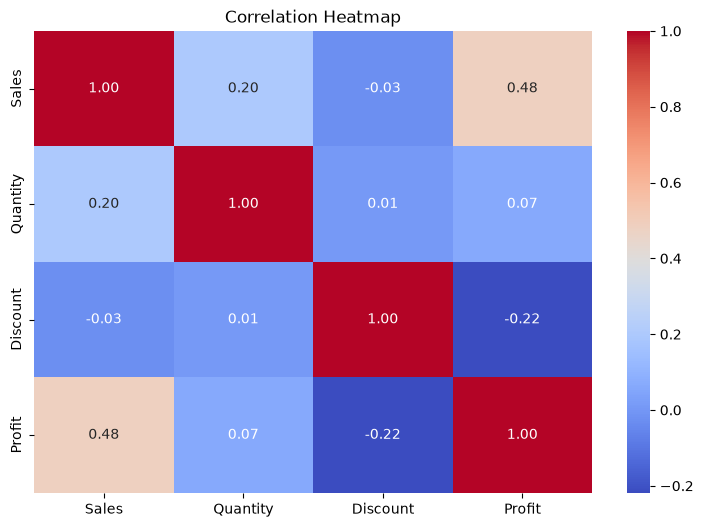

In [49]:
plt.figure(figsize=(9, 6))

correlation = cleaned_df[
    ["Sales", "Quantity", "Discount", "Profit"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
## Five Key Business Insights

**1. Technology is the Most Profitable Category**

Technology generates the highest total profit at approximately $146K, followed by Office Supplies at approximately $126K. Furniture generates significantly lower profit at approximately $20K.

**Recommendation:** Investigate Furniture's pricing, discount structure and product-level profitability.

**2. West is the Most Profitable Region**

The West region generates approximately $111K in profit, followed by East at $95K. Central records the lowest profit at approximately $40K.

**Recommendation:** Analyze the sales and cost structure of Central to identify opportunities for improvement.

**3. Sales and Profit Have a Moderate Positive Relationship**

The correlation between Sales and Profit is approximately 0.48, indicating that higher sales generally tend to be associated with higher profits.

**Recommendation:** Focus on profitable revenue growth rather than increasing sales volume alone.

**4. Discounts Show a Negative Relationship with Profit**

Discount and Profit have a correlation of approximately -0.22, suggesting a weak negative relationship.

**Recommendation:** Review high-discount transactions and evaluate whether discounting is reducing profitability.

**5. Sales Distribution is Highly Right-Skewed**

The Sales histogram shows that most transactions are concentrated in lower sales ranges, while a relatively small number of transactions have very high sales values.

**Recommendation:** Investigate high-value transactions and identify products or customers contributing to them.

### Overall Conclusion

The analysis indicates that Technology and the West region are important profit contributors. Furniture and Central require further investigation. Discount strategies and transaction-level profitability should also be monitored to improve overall business performance.

In [51]:
import os

os.makedirs("../reports/figures", exist_ok=True)

print("Figures folder created successfully!")

Figures folder created successfully!


In [52]:
plt.savefig(
    "../reports/figures/sales_histogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

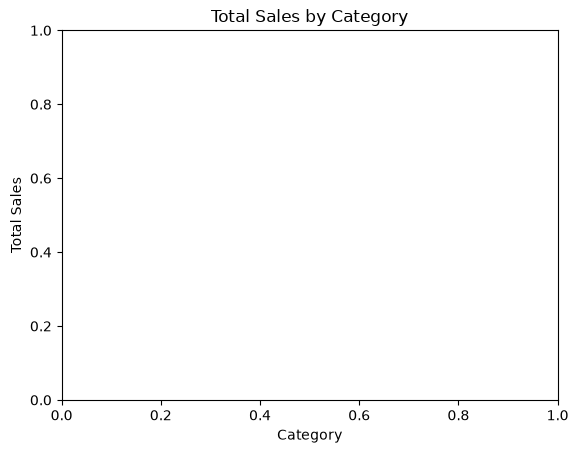

In [56]:
# Category-wise Sales
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.savefig("../reports/figures/category_sales.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [57]:
import os

os.makedirs("../reports/figures", exist_ok=True)

print("Folder created successfully!")

Folder created successfully!


In [58]:
import os

print(os.listdir("../reports/figures"))

['category_sales.png', 'region_sales.png', 'sales_histogram.png']


In [59]:
import os

print(os.listdir("../reports/figures"))

['category_sales.png', 'region_sales.png', 'sales_histogram.png']


In [60]:
plt.savefig("../reports/figures/monthly_sales.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [61]:
import os

file = "../reports/figures/monthly_sales.png"

if os.path.exists(file):
    os.remove(file)

print("Blank image removed!")

Blank image removed!


In [62]:
plt.show()

In [63]:
plt.savefig("../reports/figures/monthly_sales.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [65]:
import os

print(os.listdir("../reports/figures"))

['category_sales.png', 'monthly_sales.png', 'region_sales.png', 'sales_histogram.png']


In [66]:
# 1. Best Performing Category
category_sales = cleaned_df.groupby("Category")["Sales"].sum().sort_values(ascending=False)
print("Best Category:", category_sales.index[0])
print(category_sales)

# 2. Best Performing Region
region_sales = cleaned_df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print("\nBest Region:", region_sales.index[0])
print(region_sales)

# 3. Most Profitable Category
category_profit = cleaned_df.groupby("Category")["Profit"].sum().sort_values(ascending=False)
print("\nMost Profitable Category:", category_profit.index[0])
print(category_profit)

# 4. Most Profitable Region
region_profit = cleaned_df.groupby("Region")["Profit"].sum().sort_values(ascending=False)
print("\nMost Profitable Region:", region_profit.index[0])
print(region_profit)

# 5. Overall Business Performance
print("\nTotal Sales:", cleaned_df["Sales"].sum())
print("Total Profit:", cleaned_df["Profit"].sum())
print("Average Discount:", cleaned_df["Discount"].mean())

Best Category: Technology
Category
Technology         839893.2790
Furniture          754747.7613
Office Supplies    731893.3140
Name: Sales, dtype: float64

Best Region: West
Region
West       739813.6085
East       691828.1680
Central    503170.6728
South      391721.9050
Name: Sales, dtype: float64

Most Profitable Category: Technology
Category
Technology         146543.3756
Office Supplies    126023.4434
Furniture           19729.9956
Name: Profit, dtype: float64

Most Profitable Region: West
Region
West       110798.8170
East        94883.2603
South       46749.4303
Central     39865.3070
Name: Profit, dtype: float64

Total Sales: 2326534.3543
Total Profit: 292296.8145999999
Average Discount: 0.15538453992544635


In [67]:
business_insights = [
    "Technology is the highest-selling category with total sales of 839,893.28.",
    "West is the best-performing region with total sales of 739,813.61.",
    "Technology generates the highest profit of 146,543.38.",
    "West region generates the highest profit of 110,798.82.",
    "The business generated total sales of 2,326,534.35 and total profit of 292,296.81."
]

for i, insight in enumerate(business_insights, 1):
    print(f"Insight {i}: {insight}")

Insight 1: Technology is the highest-selling category with total sales of 839,893.28.
Insight 2: West is the best-performing region with total sales of 739,813.61.
Insight 3: Technology generates the highest profit of 146,543.38.
Insight 4: West region generates the highest profit of 110,798.82.
Insight 5: The business generated total sales of 2,326,534.35 and total profit of 292,296.81.


In [68]:
import pandas as pd
import os

insights_df = pd.DataFrame({
    "Insight No": range(1, 6),
    "Business Insights": business_insights
})

os.makedirs("../reports", exist_ok=True)

insights_df.to_csv(
    "../reports/business_insights.csv",
    index=False
)

print("Business insights saved successfully!")
display(insights_df)

Business insights saved successfully!


,Insight No,Business Insights
0,1,Technology is the highest-selling category wit...
1,2,West is the best-performing region with total ...
2,3,Technology generates the highest profit of 146...
3,4,West region generates the highest profit of 11...
4,5,"The business generated total sales of 2,326,53..."


In [69]:
import os

for root, dirs, files in os.walk("../"):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]
    print(root)
    for file in files:
        print("   ", file)

../
../dashboards
../data
../data\processed
    cleaned_superstore.csv
../data\raw
    sample_-_superstore.xls
../notebooks
    sample_-_superstore.xls
    task1_eda.ipynb
../reports
    business_insights.csv
../reports\figures
    category_sales.png
    monthly_sales.png
    region_sales.png
    sales_histogram.png
../scripts
../venv
    .gitignore
    pyvenv.cfg
../venv\etc
../venv\etc\jupyter
../venv\etc\jupyter\jupyter_notebook_config.d
    jupyterlab.json
../venv\etc\jupyter\jupyter_server_config.d
    jupyter-lsp-jupyter-server.json
    jupyterlab.json
    jupyter_server_terminals.json
    notebook.json
    notebook_shim.json
../venv\etc\jupyter\nbconfig
../venv\etc\jupyter\nbconfig\notebook.d
    widgetsnbextension.json
../venv\Include
../venv\Lib
../venv\Lib\site-packages
    ipykernel_launcher.py
    ipython_pygments_lexers.py
    jsonpointer.py
    jupyter.py
    nest_asyncio2.py
    pandocfilters.py
    pylab.py
    rfc3339_validator.py
    rfc3986_validator.py
    six.py
  

In [70]:
readme_content = """
# Superstore Data Cleaning and Exploratory Data Analysis

## Project Overview
This project focuses on cleaning and analyzing the Superstore dataset
to identify business trends and generate meaningful insights.

## Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## Project Structure

Task1_EDA/
|-- data/
|   |-- raw/
|   |-- processed/
|       |-- cleaned_superstore.csv
|-- notebooks/
|   |-- task1_eda.ipynb
|-- reports/
|   |-- business_insights.csv
|   |-- figures/
|-- dashboards/
|-- scripts/
|-- README.md

## Work Completed
1. Dataset loading and exploration
2. Missing value verification
3. Duplicate record verification
4. Data type verification
5. Outlier investigation
6. Data cleaning
7. Exploratory Data Analysis
8. Data visualization
9. Business insights generation

## Key Business Insights

1. Technology is the highest-selling category.
2. West is the best-performing sales region.
3. Technology generates the highest profit.
4. West generates the highest regional profit.
5. Total sales: 2,326,534.35
6. Total profit: 292,296.81

## Visualizations
- Sales Histogram
- Category-wise Sales
- Region-wise Sales
- Monthly Sales Trend

## Project Status
Data cleaning, EDA and business insights completed.
"""

with open("../README.md", "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!
